# ДЗ-2. От тензоров к U-Net

В сегментации модель отвечает на вопрос о **каждом пикселе**. В этом задании вы
проследите путь от RGB-картинки до логитов, соберёте небольшую U-Net и увидите её маски
на фотографиях кошек и собак из **Oxford-IIIT Pet** (Parkhi et al., CVPR 2012).
Нужно отделить **животное от фона**: белая область маски — кошка или собака,
чёрная — всё остальное. Породу и вид животного определять не нужно.

В исходной разметке три значения: животное, фон и неопределённая область у границы.
В нашем учебном наборе границу включаем в животное, получая бинарную маску.

**Восемь заданий с пропусками.** Дописывайте только места с `TODO`; после каждого
есть проверка на небольших примерах. Загрузчик данных, цикл обучения и визуализации
даны. Архитектуру собираем сами, предобученные веса не нужны.

| Оценка | Что нужно выполнить |
|---|---|
| **3** | Часть 1: оси тензоров, многоклассовое и бинарное предсказание (задания 1–3) |
| **4** | Дополнительно часть 2: свёрточный блок и U-Net (задания 4–5) |
| **5** | Дополнительно часть 3: пары картинка/маска, loss и Dice (задания 6–8), оба учебных прогона с графиками и масками |

Оценивается правильность кода; **порога качества на тесте нет**. Обучение нужно,
чтобы проверить собранную сеть и увидеть её поведение. Сначала запоминаем 4 изображения,
потом обучаем новую модель на 256 изображениях и проверяем на отложенных данных.

**Что сдавать:** этот ноутбук с вашими решениями и выводами. Для полной сдачи —
Kernel → Restart & Run All; для частичной — выполнить все ячейки до конца выбранной
части. Не меняйте проверки, разбиение данных и готовый цикл обучения.

**Где считать:** части 1–2 работают на CPU. Для обучения удобен Colab с GPU или своя
видеокарта; код автоматически выбирает CUDA, если она есть. В части 3 ноутбук
**сам скачает и распакует `oxford_pets_small.zip` (~13 МБ) с Яндекс Диска**.
Отдельно загружать данные в Colab не нужно. Если архив лежит рядом с ноутбуком
или папка `data/oxford_pets/` уже распакована, повторного скачивания не будет.
В первых двух частях интернет и датасет не нужны.

In [ ]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset

PASSED = {}
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)


def seed_all(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_all()
print("PyTorch:", torch.__version__, "| устройство:", device)

## Шпаргалка: операции с тензорами PyTorch

Этой таблицей можно пользоваться при выполнении заданий. `dim` — номер оси,
нумерация с нуля. Например, у `[B, C, H, W]` ось 0 — батч, 1 — каналы,
2 — высота, 3 (или −1) — ширина. Формы ниже — примеры, не фиксированные размеры.

**Форма, оси и тип данных**

| Операция | Что делает | Пример формы |
|---|---|---|
| `torch.from_numpy(a)` | Создаёт тензор из NumPy-массива; исходный тип сохраняется | `[2, 5, 3] → [2, 5, 3]` |
| `x.float()`, `x.long()`, `x.bool()` | Переводит в float32, int64 или bool; форму не меняет | Для чисел, индексов классов и логических масок |
| `x.permute(2, 0, 1)` | Переставляет оси: сначала бывшая ось 2, потом 0 и 1 | `[2, 5, 3] → [3, 2, 5]` |
| `x.reshape(2, 6)` | Раскладывает ту же последовательность элементов в новую форму | `[3, 4] → [2, 6]`; число элементов сохраняется |
| `x.unsqueeze(0)` | Вставляет ось длины 1 в позицию 0 | `[3, 5, 7] → [1, 3, 5, 7]` |
| `x.squeeze(1)` | Убирает ось 1, **если её длина равна 1** | `[2, 1, 5, 7] → [2, 5, 7]` |
| `x[i]`, `x[:, j]`, `x[..., k]` | Выбирает элементы; `:` берёт всю ось, `...` — все предшествующие оси | Для `[2, 3, 5]`: `x[0] → [3, 5]`, `x[:, 1] → [2, 5]` |
| `torch.cat([a, b], dim=1)` | Объединяет по **существующей** оси; остальные размеры должны совпасть | `[2, 3, 5]` и `[2, 4, 5] → [2, 7, 5]` |

**Осторожно со `squeeze()` без аргумента:** он удаляет **все** оси длины 1.
Например, `[1, 1, 5, 7] → [5, 7]`: потеряется и канал, и батч.
Если нужна конкретная ось — укажите её. `squeeze(dim)` не удаляет ось длины больше 1.
`unsqueeze` не копирует картинку несколько раз: он только добавляет единичную ось.

**Вероятности, выбор класса и суммирование**

| Операция | Что делает |
|---|---|
| `x.sigmoid()` | Поэлементно переводит логиты в вероятности; форма сохраняется |
| `x.softmax(dim=...)` | Нормирует вдоль выбранной оси: сумма по ней равна 1; форма сохраняется |
| `x.argmax(dim=...)` | Возвращает **индексы** максимумов вдоль оси; эта ось исчезает |
| `x.sum(dim=(1, 2))`, `x.mean(dim=(1, 2))` | Суммирует / усредняет по указанным осям; `[B, H, W] → [B]` |
| `keepdim=True` | В `sum`, `mean`, `argmax` сохраняет обработанную ось с длиной 1 |
| `p >= threshold` | Поэлементное сравнение: получается bool-тензор той же формы |
| `a & b` | Пересечение двух bool-масок: True там, где обе True |
| `torch.where(condition, a, b)` | Выбирает поэлементно: из `a`, если условие True, иначе из `b` |

Для изменения H и W используйте `F.interpolate`: вход `[B, C, H, W]`,
`size=(новая_высота, новая_ширина)`. Интерполяция не меняет B и C.
Для картинки / признаков пригодится `mode="bilinear", align_corners=False`,
для маски с номерами классов — `mode="nearest"`.

Справка PyTorch: [squeeze](https://docs.pytorch.org/docs/stable/generated/torch.squeeze.html),
[unsqueeze](https://docs.pytorch.org/docs/stable/generated/torch.unsqueeze.html),
[permute](https://docs.pytorch.org/docs/stable/generated/torch.permute.html).

## Часть 1. Что лежит в тензорах

Везде используем порядок PyTorch: **`[B, C, H, W]`** — батч, каналы, высота, ширина.
RGB-картинка из PIL/NumPy обычно имеет порядок `[H, W, 3]`.

Для многоклассовой сегментации `C` на выходе — число классов, включая фон.
`logits[b, c, y, x]` — **логит класса c в пикселе (y, x) картинки b**, ещё не вероятность.
У одного пикселя есть C оценок. После выбора класса маска имеет форму `[B, H, W]`:
канал классов исчез, в каждой позиции остался один целочисленный номер класса.

### Задание 1. Оси и адрес пикселя

1. Заполните `shape_plan`: в батче **4 RGB-картинки 128×192 (H×W)**, классов **5 с фоном**.
   Разметка хранит номер класса в каждом пикселе, без one-hot.
2. `image_to_tensor`: из NumPy `uint8 [H, W, 3]` сделайте `float32 [3, H, W]`
   со значениями от 0 до 1. **Переставьте оси**, сохранив цвета и координаты пикселей.
   `reshape` меняет форму, но не переставляет оси — здесь он не подходит.
3. `pixel_scores`: верните все C логитов выбранного пикселя — вектор `[C]`.

In [ ]:
# TODO: заполните три формы кортежами чисел.
shape_plan = {"input": None, "logits": None, "target": None}


def image_to_tensor(image):
    # TODO: [H, W, 3] uint8 → [3, H, W] float32, значения в [0, 1].
    raise NotImplementedError


def pixel_scores(logits, b, y, x):
    # logits: torch.Tensor [B, C, H, W] — оценки C классов для каждого пикселя батча.
    # b: индекс картинки (0 ≤ b < B); y: строка (0 ≤ y < H); x: столбец (0 ≤ x < W).
    # Вернуть torch.Tensor [C]: по одному исходному логиту на класс в пикселе (y, x)
    # картинки b. Вероятности вычислять и класс выбирать здесь не нужно.
    # TODO: все логиты в одном пикселе одной картинки, форма [C].
    raise NotImplementedError

In [ ]:
def check_axes():
    assert shape_plan == {"input": (4, 3, 128, 192), "logits": (4, 5, 128, 192),
                          "target": (4, 128, 192)}, "Разделите каналы RGB, классы и номера классов в маске"
    image = np.arange(2 * 5 * 3, dtype=np.uint8).reshape(2, 5, 3)
    t = image_to_tensor(image)
    assert t.shape == (3, 2, 5) and t.dtype == torch.float32
    for y in range(2):
        for x in range(5):
            for c in range(3):
                assert torch.isclose(t[c, y, x], torch.tensor(image[y, x, c] / 255.0).float()),                     "Форма верна, но пиксели перемешаны: нужна перестановка осей, а не reshape"
    assert image_to_tensor(np.full((3, 7, 3), 255, np.uint8)).eq(1).all()
    z = torch.arange(2 * 4 * 3 * 5).reshape(2, 4, 3, 5).float()
    v = pixel_scores(z, b=1, y=2, x=4)
    assert v.shape == (4,) and v.tolist() == [74, 89, 104, 119], "Перепутаны оси или выбран один класс"


check_axes()
PASSED[1] = True
print("✓ 1: формы, цвета и координаты сохранены")

### Задание 2. Из логитов в многоклассовую маску

В каждом пикселе ровно один из C классов. Реализуйте `decode_multiclass(logits)`:

- `probs`: softmax **по классам внутри каждого пикселя**, форма `[B, C, H, W]`;
- `mask`: номер наиболее вероятного класса, `torch.long [B, H, W]`.

Не используйте циклы по пикселям. Для выбора класса softmax необязателен:
он не меняет порядок логитов, но здесь верните и вероятности, чтобы проверить ось.

In [ ]:
def decode_multiclass(logits):
    # TODO: вероятности и номера классов; по какой оси сравниваются классы?
    raise NotImplementedError

In [ ]:
def check_multiclass():
    # Две картинки, три класса, прямоугольная сетка 2×4.
    expected = torch.tensor([[[0, 1, 2, 1], [2, 0, 1, 2]],
                             [[2, 2, 0, 1], [0, 1, 0, 2]]])
    z = torch.full((2, 3, 2, 4), -1.0)
    z.scatter_(1, expected.unsqueeze(1), 2.0)
    p, m = decode_multiclass(z)
    assert p.shape == z.shape and torch.allclose(p.sum(1), torch.ones(2, 2, 4)),         "Вероятности должны суммироваться в 1 по классам, отдельно в каждом пикселе"
    assert m.dtype == torch.long and torch.equal(m, expected), "Нужны номера классов, а не one-hot"
    assert torch.allclose(p.max(1).values, torch.full((2, 2, 4), 0.909443), atol=1e-5)
    # Добавление общей константы ко всем классам одного пикселя не меняет softmax.
    shift = torch.arange(16).reshape(2, 1, 2, 4).float()
    assert torch.allclose(decode_multiclass(z + shift)[0], p)
    p4, m4 = decode_multiclass(torch.zeros(1, 4, 3, 7))
    assert p4.shape == (1, 4, 3, 7) and torch.allclose(p4, torch.full_like(p4, .25))
    assert m4.shape == (1, 3, 7), "Не зашивайте число классов или размер батча"


check_multiclass()
PASSED[2] = True
print("✓ 2: softmax по классам, маска без оси C")

# Одна картинка: 3 класса на сетке 2×3. Сопоставьте числа с цветной маской.
toy_logits = torch.tensor([[[[3., 0., -1.], [0., 2., 0.]],
                            [[0., 4., 0.], [1., 0., 0.]],
                            [[-2., 0., 5.], [3., 0., 2.]]]])
toy_probs, toy_mask = decode_multiclass(toy_logits)
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for c, ax in enumerate(axes[:3]):
    ax.imshow(toy_probs[0, c], vmin=0, vmax=1, cmap="Blues")
    ax.set_title(f"P(класс {c})")
    for y in range(2):
        for x in range(3):
            ax.text(x, y, f"{toy_probs[0, c, y, x]:.2f}", ha="center", va="center",
                    color="white" if toy_probs[0, c, y, x] > .6 else "black")
axes[3].imshow(toy_mask[0], vmin=0, vmax=2, cmap="Set2")
axes[3].set_title("Номер класса")
for y in range(2):
    for x in range(3):
        axes[3].text(x, y, str(int(toy_mask[0, y, x])), ha="center", va="center")
for ax in axes:
    ax.set_xticks(range(3)); ax.set_yticks(range(2))
plt.tight_layout(); plt.show()

### Задание 3. Почему для двух классов бывает один канал

Для задачи «животное / фон» используем **один логит на пиксель**: выход `[B, 1, H, W]`.
Сигмоида превращает его в вероятность животного; вероятность фона равна `1 − p`.
Это другая договорённость о выходе, чем два канала с softmax; оба варианта возможны.

`decode_binary(logits, threshold)` должна вернуть:

- вероятности `float [B, 1, H, W]`;
- бинарную маску `bool [B, H, W]`: животное там, где **p ≥ threshold**.

`argmax` по единственному каналу всегда вернёт 0. `softmax` по нему всегда вернёт 1.
Они не подходят для этой модели. Снимайте **только ось канала**: батч размера 1
должен остаться батчем.

In [ ]:
def decode_binary(logits, threshold=0.5):
    # TODO: sigmoid и порог; сохранить ось батча даже при B=1.
    raise NotImplementedError

In [ ]:
def check_binary():
    z = torch.tensor([[[[-2., 0., 2.], [1., -1., 0.]]]])
    p, m = decode_binary(z)
    assert p.shape == (1, 1, 2, 3) and m.shape == (1, 2, 3), "squeeze() без оси удалил батч?"
    assert m.dtype == torch.bool
    assert torch.allclose(p[0, 0, 0], torch.tensor([.1192029, .5, .8807971]), atol=1e-6)
    assert torch.equal(m, torch.tensor([[[False, True, True], [True, False, True]]]))
    assert decode_binary(z, threshold=.8)[1].sum() == 1, "Используйте переданный порог"
    assert decode_binary(z.repeat(3, 1, 1, 1))[1].shape == (3, 2, 3)


check_binary()
PASSED[3] = True
print("✓ 3: бинарная сегментация; часть 1 завершена — уровень «3»")

## Часть 2. Собираем U-Net

Два уровня энкодера уменьшают разрешение. Декодер увеличивает его и получает
детали из энкодера через skip-связи. Здесь апсемплинг — **билинейная интерполяция**:
она меняет H и W, но сохраняет число каналов. Это отличается от транспонированных
свёрток из семинара.

### Задание 4. Свёрточный блок

Соберите `DoubleConv(c_in, c_out)`:
**Conv2d → BatchNorm2d → ReLU → Conv2d → BatchNorm2d → ReLU**.
Обе свёртки 3×3, stride=1, bias=False; выберите padding так, чтобы H и W сохранялись.
Первая переводит `c_in` каналов в `c_out`, вторая сохраняет `c_out`.

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, c_in, c_out):
        super().__init__()
        # TODO: шесть слоёв в self.block = nn.Sequential(...).
        raise NotImplementedError

    def forward(self, x):
        return self.block(x)

In [ ]:
def check_block():
    seed_all(11)
    block = DoubleConv(3, 8)
    layers = list(block.block.children())
    assert [type(m) for m in layers] == [nn.Conv2d, nn.BatchNorm2d, nn.ReLU,
                                         nn.Conv2d, nn.BatchNorm2d, nn.ReLU]
    for conv in (layers[0], layers[3]):
        assert conv.kernel_size == (3, 3) and conv.stride == (1, 1)
        assert conv.padding == (1, 1) and conv.bias is None
    x = torch.randn(2, 3, 17, 23, requires_grad=True)
    y = block(x)
    assert y.shape == (2, 8, 17, 23), "Пространственный размер должен сохраниться"
    y.square().mean().backward()
    assert x.grad is not None and x.grad.abs().sum() > 0
    assert all(p.grad is not None for p in block.parameters()), "Часть слоёв не участвует в forward"


check_block()
PASSED[4] = True
print("✓ 4: свёрточный блок сохраняет H и W, градиент проходит")

### Задание 5. Энкодер, skip-связи и декодер

На схеме показана именно наша сеть: два уменьшения разрешения и два шага декодера.
Жёлтые стрелки — skip-связи. Знаки `?` — число каналов после конкатенации,
которое вам нужно определить. Ось батча B сохраняется на всём пути.

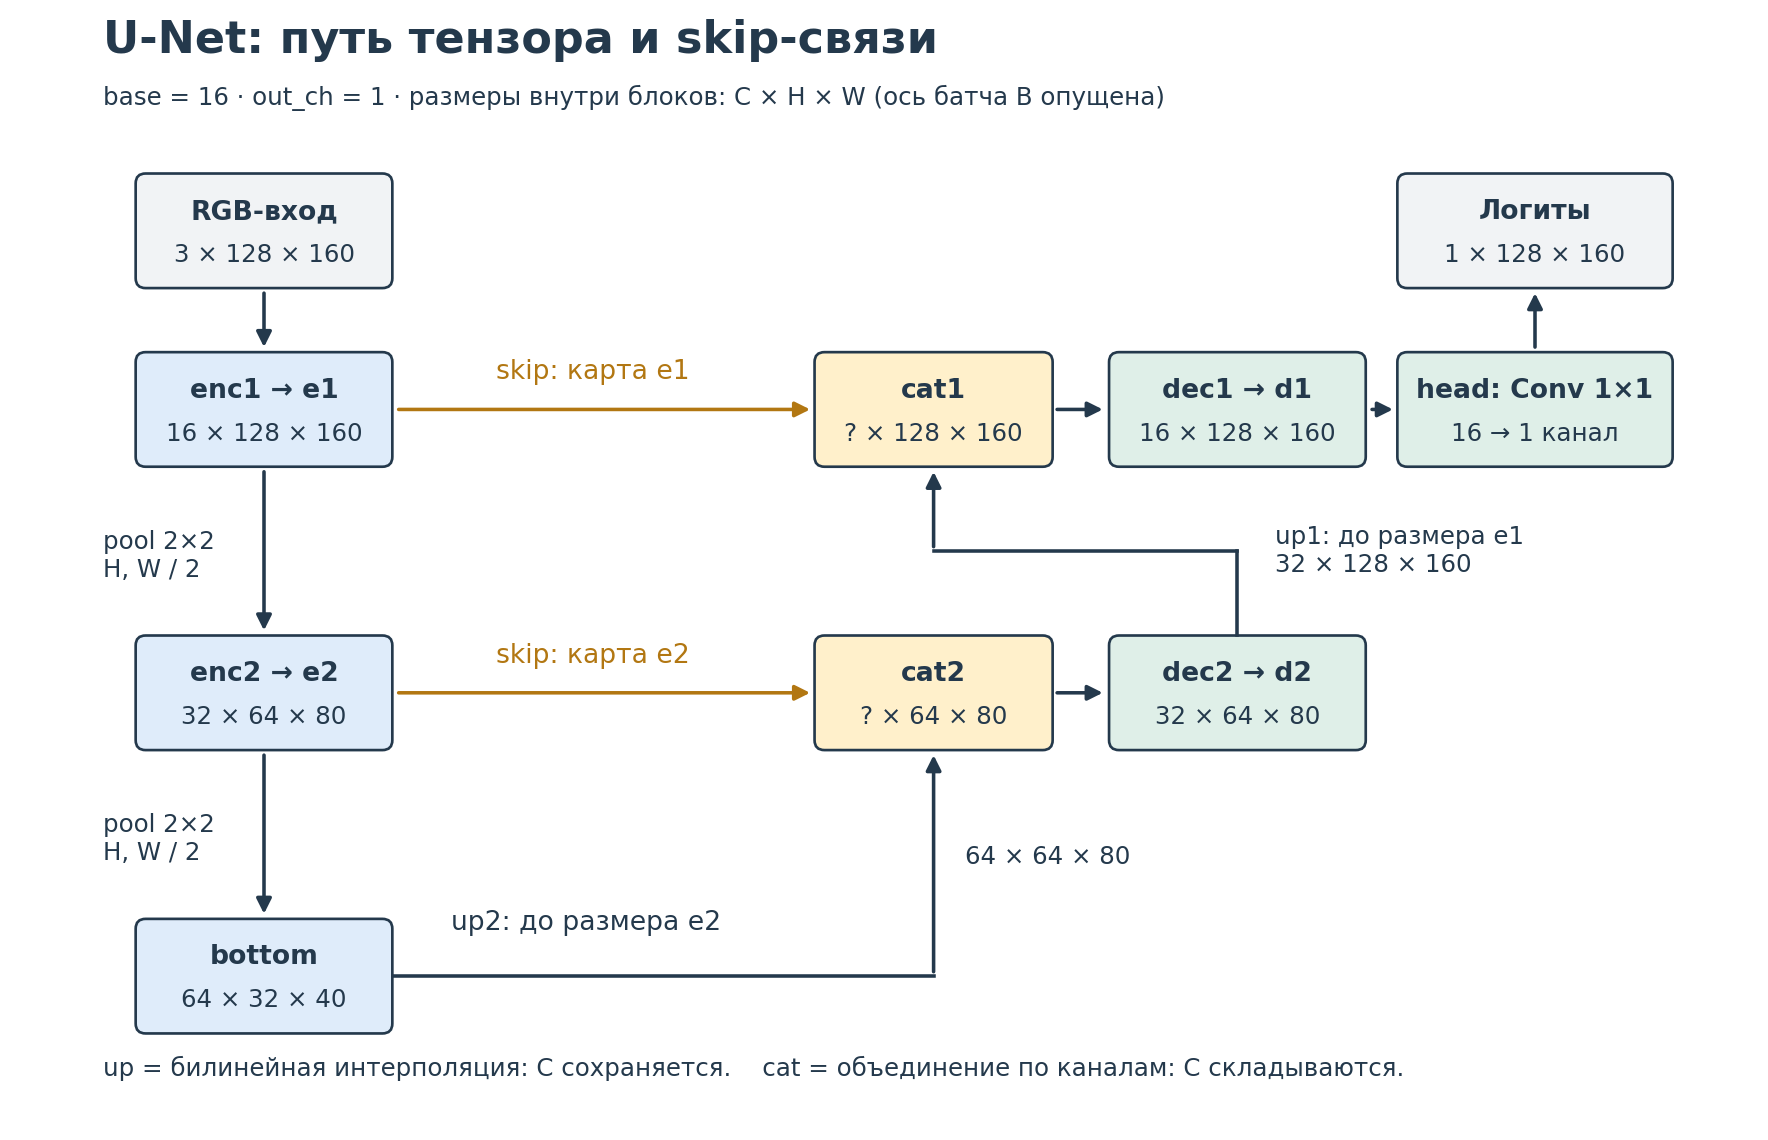

Вот формы для `base=16`, `out_ch=1` и входа `[B, 3, 128, 160]`:

| Точка | Форма | Как получили |
|---|---|---|
| e1 | `[B, 16, 128, 160]` | enc1 |
| e2 | `[B, 32, 64, 80]` | pool → enc2 |
| bottom | `[B, 64, 32, 40]` | pool → bottom |
| up2 | `[B, 64, 64, 80]` | интерполяция bottom до размера e2 |
| cat2 | `[B, ?, 64, 80]` | up2 и e2 по каналам |
| d2 | `[B, 32, 64, 80]` | dec2 |
| up1 | `[B, 32, 128, 160]` | интерполяция d2 до размера e1 |
| cat1 | `[B, ?, 128, 160]` | up1 и e1 по каналам |
| d1 | `[B, 16, 128, 160]` | dec1 |
| logits | `[B, 1, 128, 160]` | head: свёртка 1×1 |

Заполните `join_channels` для этой таблицы, затем допишите класс:

- `dec2`, `dec1` — блоки `DoubleConv`: число каналов после `cat` нужно **сложить**;
- `head` — свёртка 1×1 с `out_ch` выходными каналами;
- `forward`: энкодер → bottom → интерполяция → cat со skip → декодер, два раза;
- используйте `F.interpolate(..., size=skip.shape[-2:], mode="bilinear", align_corners=False)`;
- объединяйте по каналам. Сложение тензоров здесь не подходит: число каналов разное;
- верните **логиты без sigmoid/softmax**. Преобразование в маску уже есть в части 1.

Класс должен работать с разными `base`, `in_ch`, `out_ch` и прямоугольными входами,
в том числе нечётного размера. Поэтому поднимайте карту до **точного размера skip**,
а не всегда в два раза. Минимальный H и W в этом задании — 8.

In [ ]:
# TODO: числа каналов для таблицы с base=16.
join_channels = {"cat2": None, "cat1": None}

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, 2 * base)
        self.pool = nn.MaxPool2d(2)
        self.bottom = DoubleConv(2 * base, 4 * base)

        # TODO: self.dec2, self.dec1 и self.head; используйте base и out_ch.
        raise NotImplementedError

    def forward(self, x):
        # TODO: энкодер, bottom, два шага декодера со skip-связями, head.
        raise NotImplementedError

In [ ]:
def check_unet():
    assert join_channels == {"cat2": 96, "cat1": 48}, "При cat каналы складываются"
    seed_all(12)
    for in_ch, out_ch, base, h, w in [(3, 1, 8, 32, 48), (1, 4, 4, 31, 45)]:
        net = UNet(in_ch=in_ch, out_ch=out_ch, base=base).eval()
        assert isinstance(net.head, nn.Conv2d) and net.head.kernel_size == (1, 1)
        x = torch.randn(2, in_ch, h, w)
        # Сохраним входы декодера и выходы энкодера для проверки самих skip-связей.
        seen = {}
        def save(name):
            def hook(module, inputs, output):
                seen[name] = (inputs[0].detach().clone(), output.detach().clone())
            return hook
        handles = [getattr(net, name).register_forward_hook(save(name))
                   for name in ("enc1", "enc2", "bottom", "dec2", "dec1", "head")]
        try:
            y = net(x)
        finally:
            for handle in handles:
                handle.remove()
        assert y.shape == (2, out_ch, h, w), "Выход должен вернуться к размеру входа"
        assert torch.equal(y, seen["head"][1]), "Верните head напрямую, без sigmoid/softmax"
        for dec, enc, low in [("dec2", "enc2", "bottom"), ("dec1", "enc1", "dec2")]:
            skip = seen[enc][1]
            up = F.interpolate(seen[low][1], size=skip.shape[-2:], mode="bilinear", align_corners=False)
            actual = seen[dec][0]
            # Допустимы оба порядка конкатенации, но должны присутствовать обе карты.
            assert actual.shape[1] == up.shape[1] + skip.shape[1], "Неверное число каналов декодера"
            assert (torch.equal(actual, torch.cat([up, skip], 1)) or
                    torch.equal(actual, torch.cat([skip, up], 1))), "Skip должен попасть в декодер без подмены"
        y.square().mean().backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in net.parameters())
        assert net.enc1.block[0].weight.grad.abs().sum() > 0, "Нет градиента в начале энкодера"
    # Выход — произвольные логиты: принудительное смещение головы не должно обрезаться.
    with torch.no_grad():
        net.head.weight.zero_(); net.head.bias.fill_(-2)
        assert torch.allclose(net(x), torch.full((2, out_ch, h, w), -2.0)), "Не ограничивайте логиты"


check_unet()
PASSED[5] = True
print("✓ 5: U-Net, обе skip-связи, разные формы, backward; часть 2 — уровень «4»")

## Часть 3. Маски, loss и обучение

### Задание 6. Подготовить пару картинка/маска

В Oxford-IIIT Pet фотографии разных размеров. Для батча приведём их к **128×160 (H×W)**.
Это простое изменение пропорций для учебного опыта; все маски и метрики ниже относятся
к этой уменьшенной сетке, а не к исходному разрешению кадра.

Напишите `prepare_pair(image, mask, size)`:

- на входе NumPy: RGB `uint8 [H, W, 3]` и бинарная маска `uint8 [H, W]` из {0, 1};
- картинку преобразуйте уже написанной `image_to_tensor` и измените размер билинейно;
- маску преобразуйте в float и измените размер методом **nearest**, сохранив метки 0/1;
- верните `x: float32 [3, h, w]` и `y: float32 [1, h, w]`, оба в [0, 1].

`F.interpolate` для изображений принимает 4D тензор `[B, C, H, W]`; временно добавьте
батч из одного элемента. Аргумент `size=(h, w)` — высота, затем ширина.
Нормировки ImageNet здесь нет: сеть обучаем с нуля.

In [ ]:
def prepare_pair(image, mask, size=(128, 160)):
    # TODO: разная интерполяция для картинки и маски; формы [3,h,w] и [1,h,w].
    raise NotImplementedError

In [ ]:
def check_pair():
    mask = np.zeros((5, 9), np.uint8); mask[:, 4:] = 1
    image = np.repeat((mask * 255)[..., None], 3, axis=2)
    x, y = prepare_pair(image, mask, size=(7, 13))
    assert x.shape == (3, 7, 13) and y.shape == (1, 7, 13), "Перепутаны H и W или потерян канал маски"
    assert x.dtype == y.dtype == torch.float32
    assert set(y.unique().tolist()) == {0., 1.}, "Разметка стала дробной — нужна nearest"
    assert x.min() >= 0 and x.max() <= 1
    assert ((x > 0) & (x < 1)).any(), "У картинки должна быть билинейная интерполяция"
    assert y[..., :5].eq(0).all() and y[..., 6:].eq(1).all(), "Маска сместилась или транспонировалась"
    assert x[..., :4].eq(0).all() and x[..., 8:].eq(1).all(), "Картинка и маска не согласованы"
    x0, y0 = prepare_pair(image, mask, size=mask.shape)
    assert torch.equal(y0[0], torch.from_numpy(mask).float())
    assert torch.equal(x0, image_to_tensor(image)), "Размер уже совпадает — значения должны сохраниться"


check_pair()
PASSED[6] = True
print("✓ 6: RGB и маска приведены к одной сетке без дробных меток")

### Задание 7. Loss: BCE + soft Dice

`logits` и разметка `target` имеют форму `[B, 1, H, W]`.
Реализуйте скалярную функцию потерь:

$$L = \operatorname{BCEWithLogits}(z,y) +
\frac{1}{B}\sum_{b=1}^{B}\left(1-\frac{2\sum p_b y_b+\varepsilon}
{\sum p_b+\sum y_b+\varepsilon}\right),\qquad p=\sigma(z).$$

BCE берём готовую (`F.binary_cross_entropy_with_logits`, усреднение по умолчанию).
Для Dice суммируйте по **C, H, W отдельно для каждой картинки**, затем усредните по B.
`eps=1.0` — сглаживание и защита от нулевого знаменателя.

В BCE передаются **логиты**, в soft Dice — **вероятности**. Порог и `argmax` внутри loss
разрывают путь градиента. Сумма сразу по всему батчу тоже не подходит: она даст
другое взвешивание изображений, и крупные объекты будут сильнее влиять на Dice.

In [ ]:
def segmentation_loss(logits, target, eps=1.0):
    # TODO: BCE по логитам + soft Dice по картинкам. Вернуть скаляр-тензор.
    raise NotImplementedError

In [ ]:
def check_loss():
    # В первом кадре один положительный пиксель, во втором — все четыре.
    y = torch.tensor([[[[1., 0.], [0., 0.]]], [[[1., 1.], [1., 1.]]]])
    z = torch.zeros_like(y, requires_grad=True)
    loss = segmentation_loss(z, y)
    # При p=0.5: Dice первого кадра = 2/4, второго = 5/7.
    expected = np.log(2) + ((1 - 2/4) + (1 - 5/7)) / 2
    assert loss.ndim == 0 and abs(loss.item() - expected) < 1e-6, "Проверьте оси суммирования и sigmoid"
    separate = (segmentation_loss(z[:1], y[:1]) + segmentation_loss(z[1:], y[1:])) / 2
    assert torch.allclose(loss, separate), "Каждая картинка должна иметь одинаковый вес"
    loss.backward()
    # Аналитическая производная BCE + soft Dice в пикселе первого кадра.
    assert abs(z.grad[0, 0, 0, 0].item() - (-.109375)) < 1e-6, "Soft Dice должен участвовать в backward"
    assert z.grad[y == 1].lt(0).all() and z.grad[y == 0].gt(0).all()
    perfect = torch.where(y > 0, 20., -20.)
    assert segmentation_loss(perfect, y) < 1e-5
    empty = torch.zeros(1, 1, 2, 3)
    assert segmentation_loss(torch.full_like(empty, -20), empty) < 1e-5
    nonzero = torch.full_like(y, 1.2)
    actual = segmentation_loss(nonzero, y, eps=.3)
    p = 1 / (1 + np.exp(-1.2))
    expected_nonzero = (np.logaddexp(0, 1.2) - 1.2 * y.mean().item() +
                       1 - ((2*p + .3)/(4*p + 1 + .3) + (8*p + .3)/(4*p + 4 + .3))/2)
    assert abs(actual.item() - expected_nonzero) < 1e-6, "Проверьте eps и не подавайте sigmoid в BCEWithLogits"


check_loss()
PASSED[7] = True
print("✓ 7: значения loss, усреднение и градиенты совпадают")

### Задание 8. Метрика Dice для каждой картинки

Loss использует мягкие вероятности; метрика ниже сравнивает **готовые бинарные маски**.
На входе `pred` и `target`: `bool [B, H, W]`. Верните вектор float `[B]`:

$$\operatorname{Dice}_b=\frac{2\,|P_b\cap Y_b|}{|P_b|+|Y_b|}.$$

Если обе маски пустые, договоримся считать Dice равным 1. Если пуста только одна — 0.
Не сглаживайте непустые маски: здесь считаем метрику, не soft Dice loss.
Среднее по датасету посчитаем снаружи. Суммируйте **по пикселям**, сохраняя ось батча.

In [ ]:
def dice_per_image(pred, target):
    # TODO: [B,H,W] bool → [B] float. Обе маски пусты: Dice=1.
    raise NotImplementedError

In [ ]:
def check_dice():
    y = torch.zeros(4, 3, 5, dtype=torch.bool)
    p = y.clone()
    y[0, 0, :3] = True; p[0, 0, 1:4] = True  # пересечение 2, сумма площадей 6
    y[1, 1, 1] = True                         # пропущен объект
    p[3, 2, 2] = True                         # ложный объект
    result = dice_per_image(p, y)
    assert result.shape == (4,) and result.is_floating_point(), "Верните один Dice на картинку"
    assert torch.allclose(result, torch.tensor([2/3, 0., 1., 0.])), "Проверьте пересечение и пустые маски"
    assert torch.allclose(result, dice_per_image(y, p)), "Dice симметричен"
    assert torch.allclose(dice_per_image(y, y), torch.ones(4))


check_dice()
PASSED[8] = True
print("✓ 8: Dice по картинкам; осталось проверить сеть в обучении")

## Задания с пропусками закончились. Проверяем модель в работе

**`dice_per_image` (задание 8) — последняя функция, которую вы дописываете.**
Дальше весь код готов: последовательно выполните загрузку данных, два опыта обучения
и финальную проверку. Для полной сдачи сохраните выводы и рассмотрите графики и маски;
писать новые функции или отдельный отчёт не нужно.

### Данные: фотографии животных и маски

Используем **556 фотографий**: 256 train, 100 val, 200 test. В каждой части поровну
кошек и собак. Train и val взяты без пересечений из официальной части trainval,
а test — из официального test. Список и порядок файлов зафиксированы в `manifest.json`.
Тест не участвует в выборе эпохи; в конце один раз оценим лучшую по val модель.

Для компактности фотографии заранее уменьшены до длинной стороны не более 320 пикселей
с сохранением пропорций. Затем ваша функция `prepare_pair` приведёт их к 128×160.
Маски в пакете уже бинарные: исходные метки 1 (животное) и 3 (неопределённая область
у границы) объединены в белую область, метка 2 (фон) стала чёрной.
Это учебная договорённость; мы не пытаемся точно оценивать неопределённую границу.

Ячейка использует готовую папку `data/oxford_pets/` или локальный архив
`oxford_pets_small.zip`. Если их нет, она скачает компактный архив по публичной
ссылке Яндекс Диска, проверит SHA-256 и распакует его. Полный исходный датасет
(~800 МБ) не нужен. Если сеть недоступна, можно скачать архив по [ссылке](https://yadi.sk/d/fDSEkvQAkBJT_w)
вручную и положить рядом с ноутбуком; в Colab — через «Файлы» → «Загрузить».

[Страница датасета и примеры разметки](https://www.robots.ox.ac.uk/~vgg/data/pets/).
Авторы: O. M. Parkhi, A. Vedaldi, A. Zisserman, C. V. Jawahar; *Cats and Dogs*, CVPR 2012.
На странице источника указана лицензия CC BY-SA 4.0; атрибуция и описание изменений
сохранены в `data/oxford_pets/README.txt`.

In [ ]:
import hashlib
import json
import shutil
import urllib.parse
import urllib.request
import zipfile

DATA_URL = "https://yadi.sk/d/fDSEkvQAkBJT_w"
ARCHIVE_SHA256 = "dca32ad4c66ac8b59cc30f992946c90e2719eef4509feb4b3e5fbbc0ef9d06ca"
DATA = Path("data/oxford_pets")
DATASET_ID = "oxford-pets-small-v1"


def download_archive(public_url, archive):
    # Публичная ссылка Яндекс Диска → проверенный ZIP; токен не нужен.
    api = "https://cloud-api.yandex.net/v1/disk/public/resources/download?public_key="
    with urllib.request.urlopen(api + urllib.parse.quote(public_url, safe=""), timeout=60) as response:
        href = json.load(response)["href"]
    partial = archive.with_suffix(archive.suffix + ".part")
    print("Скачиваем oxford_pets_small.zip (~13 МБ)…")
    try:
        with urllib.request.urlopen(href, timeout=60) as response, partial.open("wb") as output:
            shutil.copyfileobj(response, output)
        if hashlib.sha256(partial.read_bytes()).hexdigest() != ARCHIVE_SHA256:
            raise ValueError("Архив скачался не полностью или повреждён. Повторите ячейку.")
        partial.replace(archive)
    finally:
        partial.unlink(missing_ok=True)


def ensure_data():
    if not (DATA / "manifest.json").is_file():
        archive = Path("oxford_pets_small.zip")
        if not archive.exists():
            download_archive(DATA_URL, archive)
        if hashlib.sha256(archive.read_bytes()).hexdigest() != ARCHIVE_SHA256:
            raise ValueError("Неверный oxford_pets_small.zip: нужен архив по ссылке из этого ДЗ.")
        with zipfile.ZipFile(archive) as z:
            for name in z.namelist():
                if not name.startswith("data/oxford_pets/") or ".." in Path(name).parts:
                    raise ValueError("Неверный архив: ожидался учебный Oxford Pets")
            z.extractall(".")
    manifest = json.loads((DATA / "manifest.json").read_text())
    assert manifest["dataset"] == DATASET_ID, "Нужна версия oxford-pets-small-v1"
    for split, count in [("train", 256), ("val", 100), ("test", 200)]:
        names = manifest["splits"][split]
        assert len(names) == len(set(names)) == count, f"Неверный split {split}"
        for name in names:
            assert (DATA / split / "images" / f"{name}.jpg").is_file(), name
            assert (DATA / split / "masks" / f"{name}.png").is_file(), name
    return manifest


manifest = ensure_data()
train_ids, val_ids, test_ids = [manifest["splits"][s] for s in ("train", "val", "test")]
assert not (set(train_ids) & set(val_ids) or set(train_ids) & set(test_ids) or set(val_ids) & set(test_ids))
SIZE = (128, 160)  # H, W


def load_split(ids, split):
    pairs = []
    for name in ids:
        with Image.open(DATA / split / "images" / f"{name}.jpg") as image:
            rgb = np.asarray(image.convert("RGB"))
        with Image.open(DATA / split / "masks" / f"{name}.png") as mask:
            binary = (np.asarray(mask.convert("L")) > 127).astype(np.uint8)
        pairs.append(prepare_pair(rgb, binary, SIZE))
    return torch.stack([p[0] for p in pairs]), torch.stack([p[1] for p in pairs])


X_train, Y_train = load_split(train_ids, "train")
X_val, Y_val = load_split(val_ids, "val")
print("train:", tuple(X_train.shape), tuple(Y_train.shape))
print("val:  ", tuple(X_val.shape), tuple(Y_val.shape))
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for j in range(4):
    axes[0, j].imshow(X_train[j].permute(1, 2, 0)); axes[0, j].set_title(f"Кадр {j}")
    axes[1, j].imshow(Y_train[j, 0], cmap="gray", vmin=0, vmax=1); axes[1, j].set_title("Маска: животное / фон")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Готовый цикл обучения

Здесь пропусков нет. В цикле используются **ваши** U-Net, loss, декодирование и Dice.
Порог фиксируем на 0.5. Для метрики сначала получаем один Dice на картинку, затем
усредняем по всем изображениям — размер последнего батча не меняет их вес.

In [ ]:
@torch.no_grad()
def evaluate(model, X, Y, batch_size=32):
    model.eval()
    scores = []
    masks = []
    for start in range(0, len(X), batch_size):
        logits = model(X[start:start + batch_size].to(device))
        _, pred = decode_binary(logits)
        scores.append(dice_per_image(pred, Y[start:start + batch_size, 0].to(device).bool()).cpu())
        masks.append(pred.cpu())
    return torch.cat(scores), torch.cat(masks)


def show_predictions(X, Y, pred, title, indices=None):
    indices = list(range(min(4, len(X)))) if indices is None else list(indices)
    fig, axes = plt.subplots(len(indices), 3, figsize=(9, 2.4 * len(indices)), squeeze=False)
    scores = dice_per_image(pred, Y[:, 0].bool())
    for row, i in enumerate(indices):
        axes[row, 0].imshow(X[i].permute(1, 2, 0))
        axes[row, 1].imshow(Y[i, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, 2].imshow(pred[i], cmap="gray", vmin=0, vmax=1)
        axes[row, 0].set_title(f"Картинка {i}")
        axes[row, 1].set_title("Разметка")
        axes[row, 2].set_title(f"Предсказание · Dice {scores[i]:.2f}")
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color("0.7")  # рамка видна даже у полностью белой маски
    fig.suptitle(title)
    plt.tight_layout(); plt.show()


def train_step(model, optimizer, x, y):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    logits = model(x)
    loss = segmentation_loss(logits, y)
    if not torch.isfinite(loss):
        raise ValueError("Loss стал NaN/Inf: проверьте формулу и нормировку")
    loss.backward()
    optimizer.step()
    return loss.item()

### Опыт 1. Может ли сеть запомнить четыре картинки?

Это проверка исправности обучения. Берём первые 4 **обучающих** изображения,
без аугментаций, и делаем 200 шагов Adam на одном и том же батче. Смотрим loss,
Dice на этих же картинках и предсказания до/после.

Хороший результат здесь означает, что сеть научилась **запоминать** эти примеры.
Он ничего не доказывает о качестве на новых данных. Если loss не падает и маски
остаются пустыми, сначала проверьте оси, loss и путь градиента, прежде чем учить дольше.
Dice после порога может быть близок к 1, пока loss ещё заметно выше нуля:
класс уже выбран верно, но вероятности пока не близки к 0 и 1.

In [ ]:
seed_all(0)
tiny_model = UNet().to(device)
x_tiny, y_tiny = X_train[:4].to(device), Y_train[:4].to(device)
tiny_before, pred_before = evaluate(tiny_model, X_train[:4], Y_train[:4])
optimizer = torch.optim.Adam(tiny_model.parameters(), lr=1e-3)
tiny_losses = []
t0 = time.perf_counter()
for step in range(200):
    tiny_losses.append(train_step(tiny_model, optimizer, x_tiny, y_tiny))
tiny_after, pred_after = evaluate(tiny_model, X_train[:4], Y_train[:4])
TINY_SECONDS = time.perf_counter() - t0
print(f"4 обучающих кадра: Dice {tiny_before.mean():.3f} → {tiny_after.mean():.3f}")
print(f"Loss: {tiny_losses[0]:.3f} → {tiny_losses[-1]:.3f}; время {TINY_SECONDS:.1f} с")
plt.figure(figsize=(7, 3)); plt.plot(range(1, 201), tiny_losses)
plt.xlabel("Шаг на одном батче"); plt.ylabel("BCE + soft Dice"); plt.title("Запоминание четырёх кадров")
plt.grid(alpha=.2); plt.tight_layout(); plt.show()
show_predictions(X_train[:4], Y_train[:4], pred_before, "До обучения: первые 4 train-кадра")
show_predictions(X_train[:4], Y_train[:4], pred_after, "После 200 шагов: те же 4 train-кадра")
# Это диагностика, не порог оценки. Никакого подбора по test здесь нет.
if tiny_after.mean() < .85:
    print("Диагностика: Dice на четырёх кадрах невысок. Проверьте loss и маски перед следующим опытом.")

### Опыт 2. Короткое обучение и проверка на новых изображениях

Создаём **новую** U-Net со случайными весами: модель из опыта на четырёх картинках
не продолжаем. Учим 20 эпох на 256 кадрах, сохраняем лучшие веса по среднему Dice
на 100 val-кадрах. Аугментации здесь не используем, чтобы сосредоточиться на сети и loss.

Качество на val может колебаться и уступать train. Задача — увидеть разницу между
запоминанием и обобщением, а не достичь результата большой предобученной модели.

In [ ]:
seed_all(1)
model = UNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=16, shuffle=True,
                    generator=torch.Generator().manual_seed(1), num_workers=0)
initial_val, _ = evaluate(model, X_val, Y_val)
history = []
best_val, best_state, best_epoch = -1.0, None, None
EPOCHS = 20
t0 = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    total_loss = 0.0
    for x, y in loader:
        total_loss += train_step(model, optimizer, x.to(device), y.to(device)) * len(x)
    train_scores, _ = evaluate(model, X_train, Y_train)
    val_scores, _ = evaluate(model, X_val, Y_val)
    row = (total_loss / len(X_train), train_scores.mean().item(), val_scores.mean().item())
    history.append(row)
    if row[2] > best_val:
        best_val, best_epoch = row[2], epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if epoch == 1 or epoch % 5 == 0:
        print(f"Эпоха {epoch:2d}: loss {row[0]:.3f} | train Dice {row[1]:.3f} | val Dice {row[2]:.3f}")
TRAIN_SECONDS = time.perf_counter() - t0
model.load_state_dict(best_state)
print(f"Val до обучения: {initial_val.mean():.3f}; лучший: {best_val:.3f}, эпоха {best_epoch}")
print(f"Обучение и валидация: {TRAIN_SECONDS:.1f} с")
Path("checkpoints").mkdir(exist_ok=True)
torch.save({"model": best_state, "epoch": best_epoch, "size": SIZE}, "checkpoints/hw2_unet.pt")
h = np.asarray(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(range(1, EPOCHS + 1), h[:, 0]); axes[0].set_ylabel("BCE + soft Dice")
axes[0].set_title("Loss на train")
axes[1].plot(range(1, EPOCHS + 1), h[:, 1], label="train")
axes[1].plot(range(1, EPOCHS + 1), h[:, 2], label="val")
axes[1].set_ylabel("Средний Dice"); axes[1].set_ylim(0, 1); axes[1].legend()
axes[1].set_title("Качество на обучающих и новых кадрах")
for ax in axes:
    ax.set_xlabel("Эпоха"); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
val_scores, val_pred = evaluate(model, X_val, Y_val)
show_predictions(X_val, Y_val, val_pred, "Лучшие по val веса: первые 4 val-кадра")
worst = val_scores.argsort()[:4].tolist()
show_predictions(X_val, Y_val, val_pred, "Те же веса: 4 худших val-кадра", indices=worst)

### Финальная проверка на test

Веса и порог уже выбраны. Теперь один раз считаем test Dice на 200 отложенных кадрах.
Метрика считается на сетке **128×160** и потому не сравнивается напрямую с результатами
в исходном разрешении или со старой версией этого ДЗ.

Посмотрите на маски: сеть пропускает объект целиком, захватывает лишнее или ошибается
только на границе? Высокое качество на четырёх train-картинках не гарантирует хороших
масок на test. Отдельный письменный отчёт не нужен — сдайте код и эти визуализации.

In [ ]:
X_test, Y_test = load_split(test_ids, "test")
test_scores, test_pred = evaluate(model, X_test, Y_test)
TEST_DICE = test_scores.mean().item()
print(f"Test: {len(test_ids)} кадров, средний Dice {TEST_DICE:.3f}")
show_predictions(X_test, Y_test, test_pred, "Первые 4 test-кадра; порог 0.5")
RUNS_DONE = (len(tiny_losses) == 200 and len(history) == EPOCHS and
             np.isfinite(history).all() and torch.isfinite(test_scores).all().item())

## Итог

Все восемь проверок должны пройти. Для полной сдачи нужны также выполненные опыты
и визуализации. Число Dice не определяет оценку: основное — корректные операции
с тензорами, рабочая архитектура и правильные loss/метрика.

**Проверьте своё понимание по коду:** где RGB-каналы становятся каналами признаков,
где появляются логиты классов, почему после `cat` больше каналов и почему loss
получает не ту бинарную маску, которую мы показываем на картинке.

In [ ]:
print("Проверки заданий:", f"{sum(PASSED.get(i, False) for i in range(1, 9))}/8")
for grade, required in [(3, range(1, 4)), (4, range(1, 6)), (5, range(1, 9))]:
    ok = all(PASSED.get(i, False) for i in required)
    if grade == 5:
        ok = ok and globals().get("RUNS_DONE", False)
    print(f"Уровень «{grade}»: {'выполнен' if ok else 'не завершён'}")